# EDA

In [99]:
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [100]:
df = pd.read_csv("../data/virat_odi_data.csv")

In [101]:
df

,Runs,Mins,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date
0,12,33,22,1,0,54.54,2,lbw,1,v Sri Lanka,Dambulla,18 Aug 2008
1,37,82,67,6,0,55.22,2,caught,2,v Sri Lanka,Dambulla,20 Aug 2008
2,25,40,38,4,0,65.78,1,run out,1,v Sri Lanka,Colombo (RPS),24 Aug 2008
3,54,87,66,7,0,81.81,1,bowled,1,v Sri Lanka,Colombo (RPS),27 Aug 2008
4,31,45,46,3,1,67.39,1,lbw,2,v Sri Lanka,Colombo (RPS),29 Aug 2008
...,...,...,...,...,...,...,...,...,...,...,...,...
306,102,143,93,7,2,109.67,3,caught,1,v South Africa,Raipur,3 Dec 2025
307,65*,57,45,6,3,144.44,3,not out,2,v South Africa,Visakhapatnam,6 Dec 2025
308,93,123,91,8,1,102.19,3,caught,2,v New Zealand,Vadodara,11 Jan 2026
309,23,43,29,2,0,79.31,3,bowled,1,v New Zealand,Rajkot,14 Jan 2026


In [102]:
df.shape

(311, 12)

In [103]:
df.describe()

,Runs,Mins,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date
count,311,311,311,311,311,311,311,311,311,311,311,311
unique,153,144,117,22,9,219,8,8,3,14,69,311
top,0,-,-,0,0,0,3,caught,2,v Sri Lanka,Mirpur,18 Aug 2008
freq,18,49,12,58,207,17,244,178,171,56,16,1


In [104]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Runs        311 non-null    str  
 1   Mins        311 non-null    str  
 2   BF          311 non-null    str  
 3   4s          311 non-null    str  
 4   6s          311 non-null    str  
 5   SR          311 non-null    str  
 6   Pos         311 non-null    str  
 7   Dismissal   311 non-null    str  
 8   Inns        311 non-null    str  
 9   Opposition  311 non-null    str  
 10  Ground      311 non-null    str  
 11  Start Date  311 non-null    str  
dtypes: str(12)
memory usage: 29.3 KB


In [105]:
df.isnull().sum()

Runs          0
Mins          0
BF            0
4s            0
6s            0
SR            0
Pos           0
Dismissal     0
Inns          0
Opposition    0
Ground        0
Start Date    0
dtype: int64

In [106]:
df.columns

Index(['Runs', 'Mins', 'BF', '4s', '6s', 'SR', 'Pos', 'Dismissal', 'Inns',
       'Opposition', 'Ground', 'Start Date'],
      dtype='str')

In [107]:
df['Runs'].value_counts().sort_values(ascending=False)

Runs
0      18
2       8
DNB     8
31      7
9       7
       ..
74*     1
135     1
65*     1
93      1
124     1
Name: count, Length: 153, dtype: int64

In [108]:
df = df[~df['Runs'].isin(['DNB','TDNB'])]

In [109]:
df.shape

(299, 12)

In [110]:
df['Runs'].value_counts()

Runs
0      18
2       8
31      7
9       7
8       7
       ..
74*     1
135     1
65*     1
93      1
124     1
Name: count, Length: 151, dtype: int64

In [111]:
df['NotOut'] = df['Runs'].astype(str).str.contains(r"\*")

In [112]:
df[['Runs','NotOut']]

,Runs,NotOut
0,12,False
1,37,False
2,25,False
3,54,False
4,31,False
...,...,...
306,102,False
307,65*,True
308,93,False
309,23,False


In [113]:
df['Runs'] = df['Runs'].astype(str).str.replace("*","",regex=False).astype(int)

In [114]:
df['Runs'].value_counts()

Runs
0      18
2       9
31      7
9       7
8       7
       ..
84      1
74      1
135     1
93      1
124     1
Name: count, Length: 127, dtype: int64

In [115]:
df['Mins'].value_counts()

Mins
-      37
6       7
12      6
11      5
9       5
       ..
149     1
74      1
151     1
111     1
143     1
Name: count, Length: 144, dtype: int64

In [116]:
df['Mins'] = df['Mins'].replace("-",np.nan)
df['Mins'] = pd.to_numeric(df['Mins'])

In [117]:
df['Mins'].value_counts()

Mins
6.0      7
12.0     6
11.0     5
9.0      5
19.0     4
        ..
149.0    1
74.0     1
151.0    1
111.0    1
143.0    1
Name: count, Length: 143, dtype: int64

In [118]:
df['BF'].value_counts()

BF
5      11
8       8
9       8
18      8
22      6
       ..
77      1
15      1
110     1
7       1
32      1
Name: count, Length: 116, dtype: int64

In [119]:
df['BF'] = df['BF'].astype(int)

In [120]:
df['BF'].info()

<class 'pandas.Series'>
Index: 299 entries, 0 to 310
Series name: BF
Non-Null Count  Dtype
--------------  -----
299 non-null    int64
dtypes: int64(1)
memory usage: 4.7 KB


In [121]:
df['4s'].value_counts()

4s
0     58
1     39
2     30
3     24
4     22
5     21
7     18
6     17
9     16
8     13
11     9
10     8
13     6
16     5
12     5
14     3
22     1
18     1
17     1
19     1
21     1
Name: count, dtype: int64

In [122]:
df['6s'].value_counts()

6s
0    207
1     51
2     26
3      7
4      3
7      2
5      2
8      1
Name: count, dtype: int64

In [123]:
df['4s'] = df['4s'].astype(int)
df['6s'] = df['6s'].astype(int)

In [124]:
df['SR'].value_counts()

SR
0         17
100        7
66.66      7
25         6
50         6
          ..
109.67     1
144.44     1
102.19     1
79.31      1
114.81     1
Name: count, Length: 219, dtype: int64

In [125]:
df['SR'] = df['SR'].replace('-',np.nan)
df['SR'] = pd.to_numeric(df['SR'])

In [126]:
df['SR'].info()

<class 'pandas.Series'>
Index: 299 entries, 0 to 310
Series name: SR
Non-Null Count  Dtype  
--------------  -----  
298 non-null    float64
dtypes: float64(1)
memory usage: 4.7 KB


In [127]:
df['Pos'].value_counts()

Pos
3    244
4     39
1      4
7      4
5      4
2      3
6      1
Name: count, dtype: int64

In [128]:
df['Pos'] = df['Pos'].astype(int)

In [129]:
df.head()

,Runs,Mins,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date,NotOut
0,12,33.0,22,1,0,54.54,2,lbw,1,v Sri Lanka,Dambulla,18 Aug 2008,False
1,37,82.0,67,6,0,55.22,2,caught,2,v Sri Lanka,Dambulla,20 Aug 2008,False
2,25,40.0,38,4,0,65.78,1,run out,1,v Sri Lanka,Colombo (RPS),24 Aug 2008,False
3,54,87.0,66,7,0,81.81,1,bowled,1,v Sri Lanka,Colombo (RPS),27 Aug 2008,False
4,31,45.0,46,3,1,67.39,1,lbw,2,v Sri Lanka,Colombo (RPS),29 Aug 2008,False


# Data Visualisation

# Target Variable Analysis

<Axes: xlabel='Runs', ylabel='Count'>

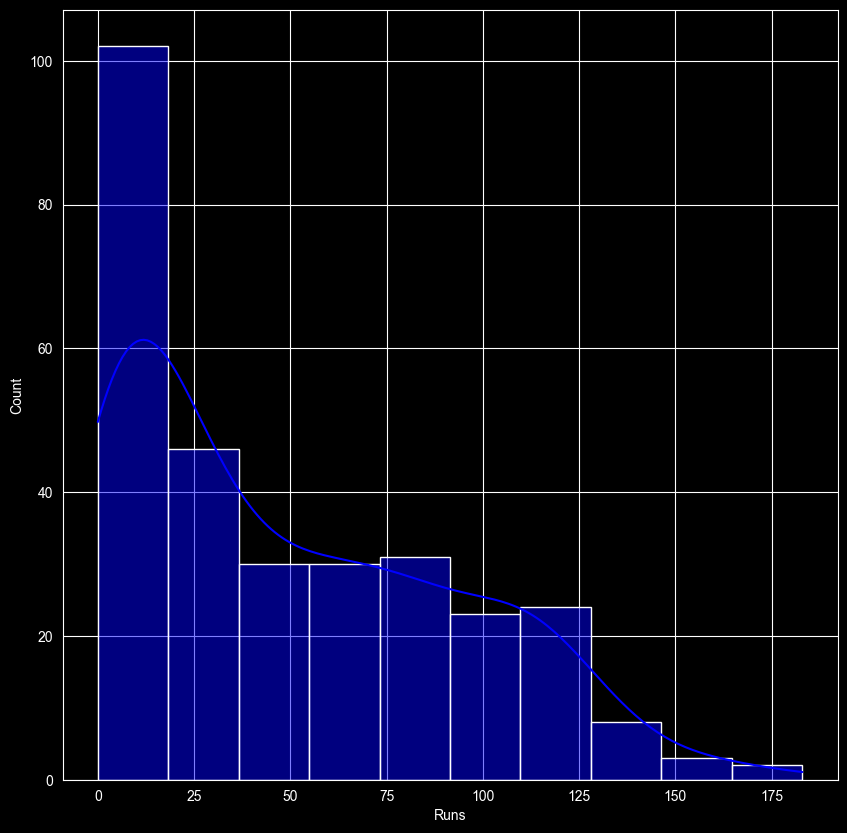

In [130]:
plt.figure(figsize=(10,10))
sns.histplot(df['Runs'], color='blue', kde=True)

<Axes: ylabel='Runs'>

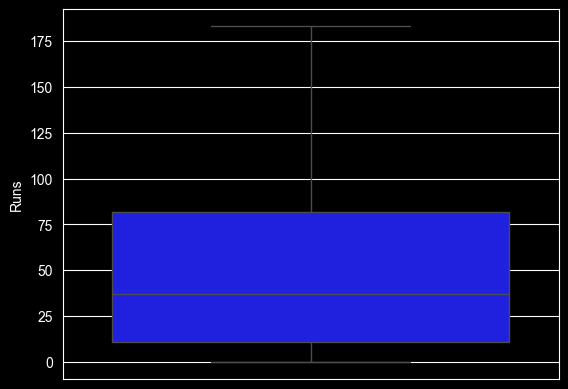

In [131]:
sns.boxplot(df['Runs'],color='blue')

# Opposition Analysis

Text(0.5, 1.0, 'Average runs scored against an opposition')

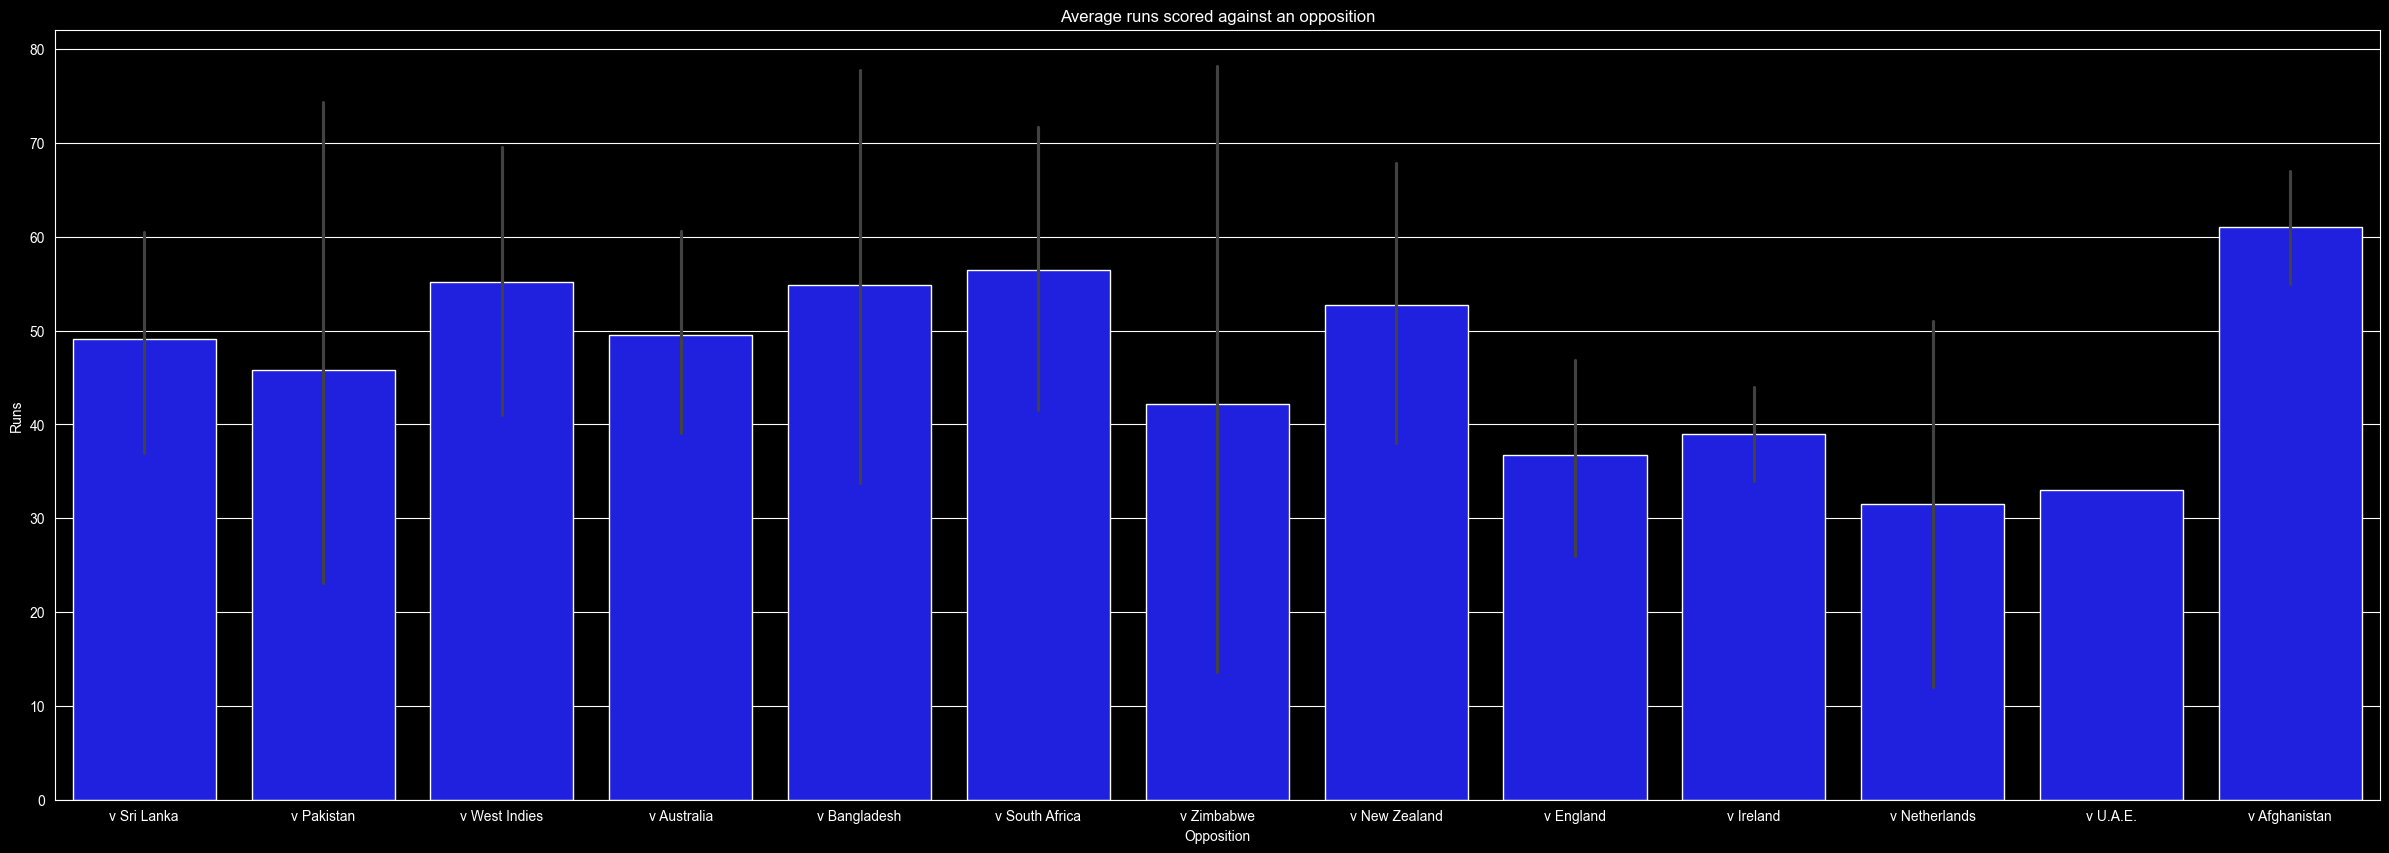

In [132]:
plt.figure(figsize=(30,10))
sns.barplot(data=df, x='Opposition', y='Runs', color='blue')
plt.title('Average runs scored against an opposition')

<Axes: xlabel='Opposition', ylabel='Runs'>

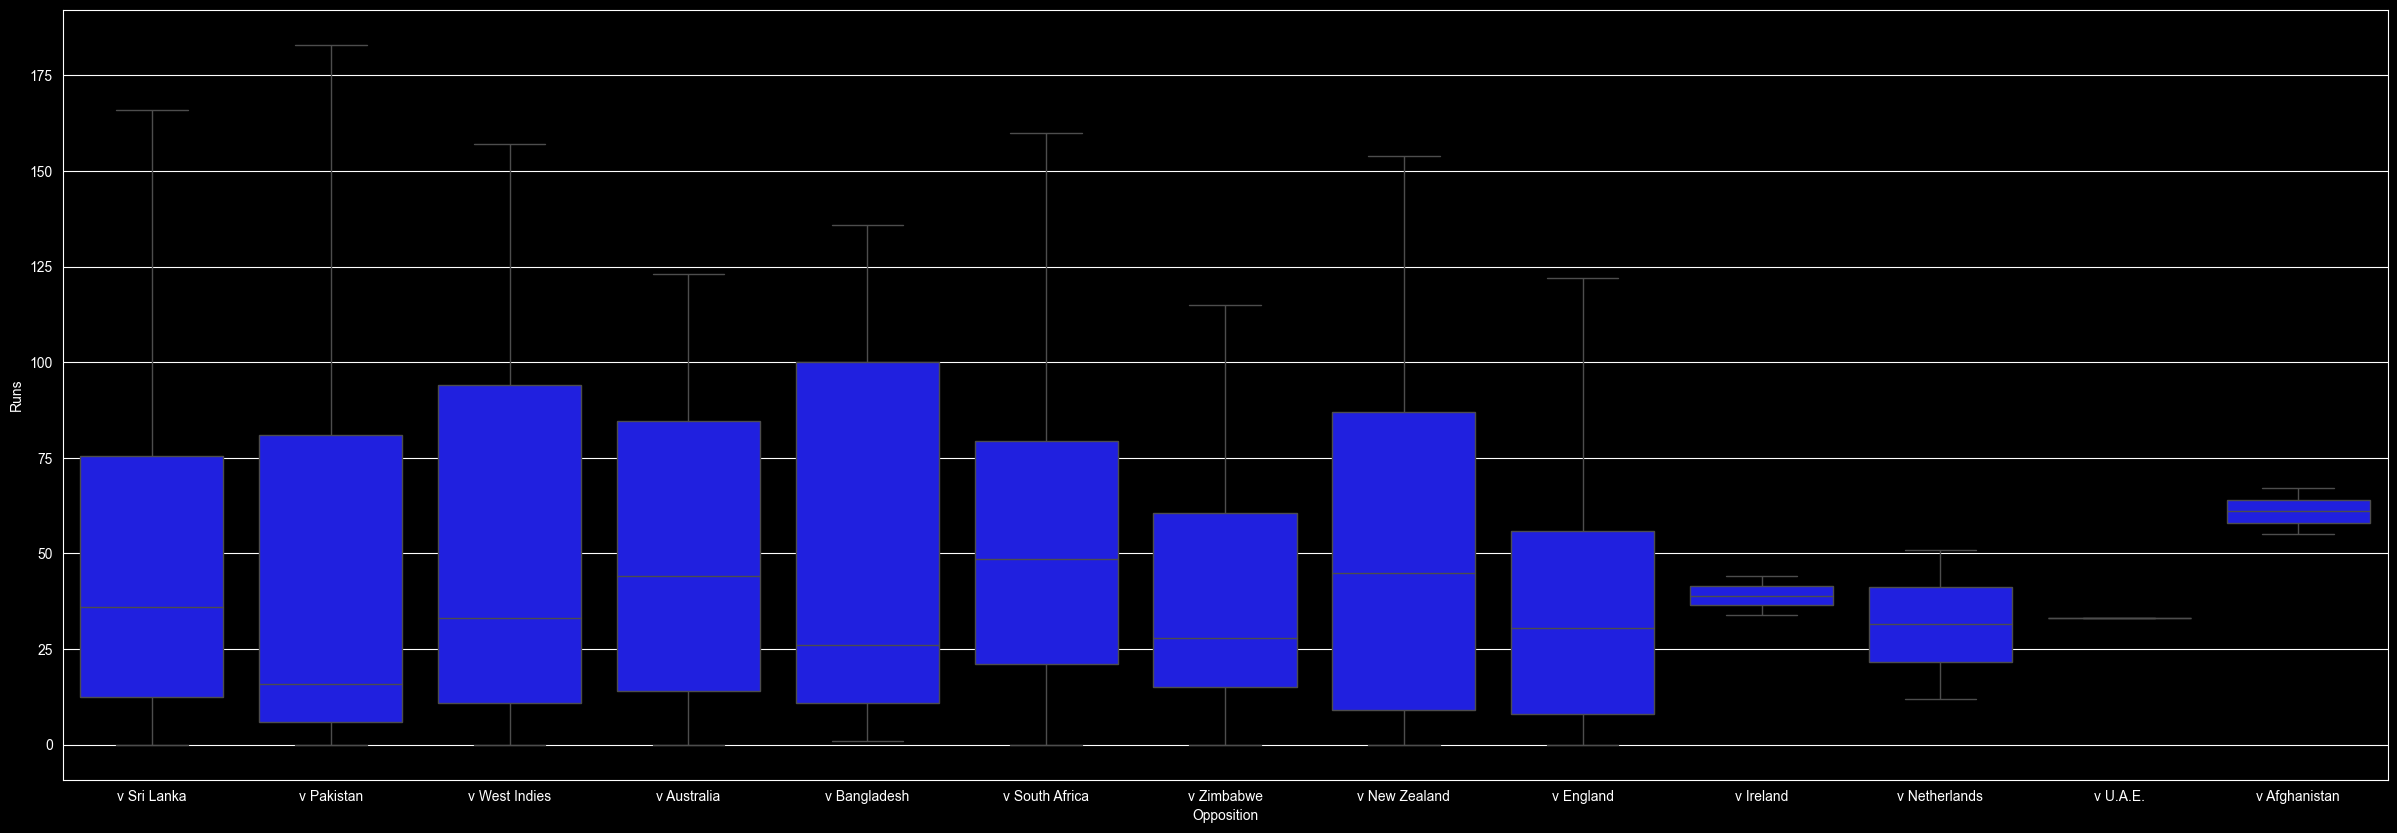

In [133]:
plt.figure(figsize=(30,10))
sns.boxplot(data=df, x='Opposition', y='Runs', color='blue')

# Venue Analysis

Text(0.5, 1.0, 'Average runs on a Ground')

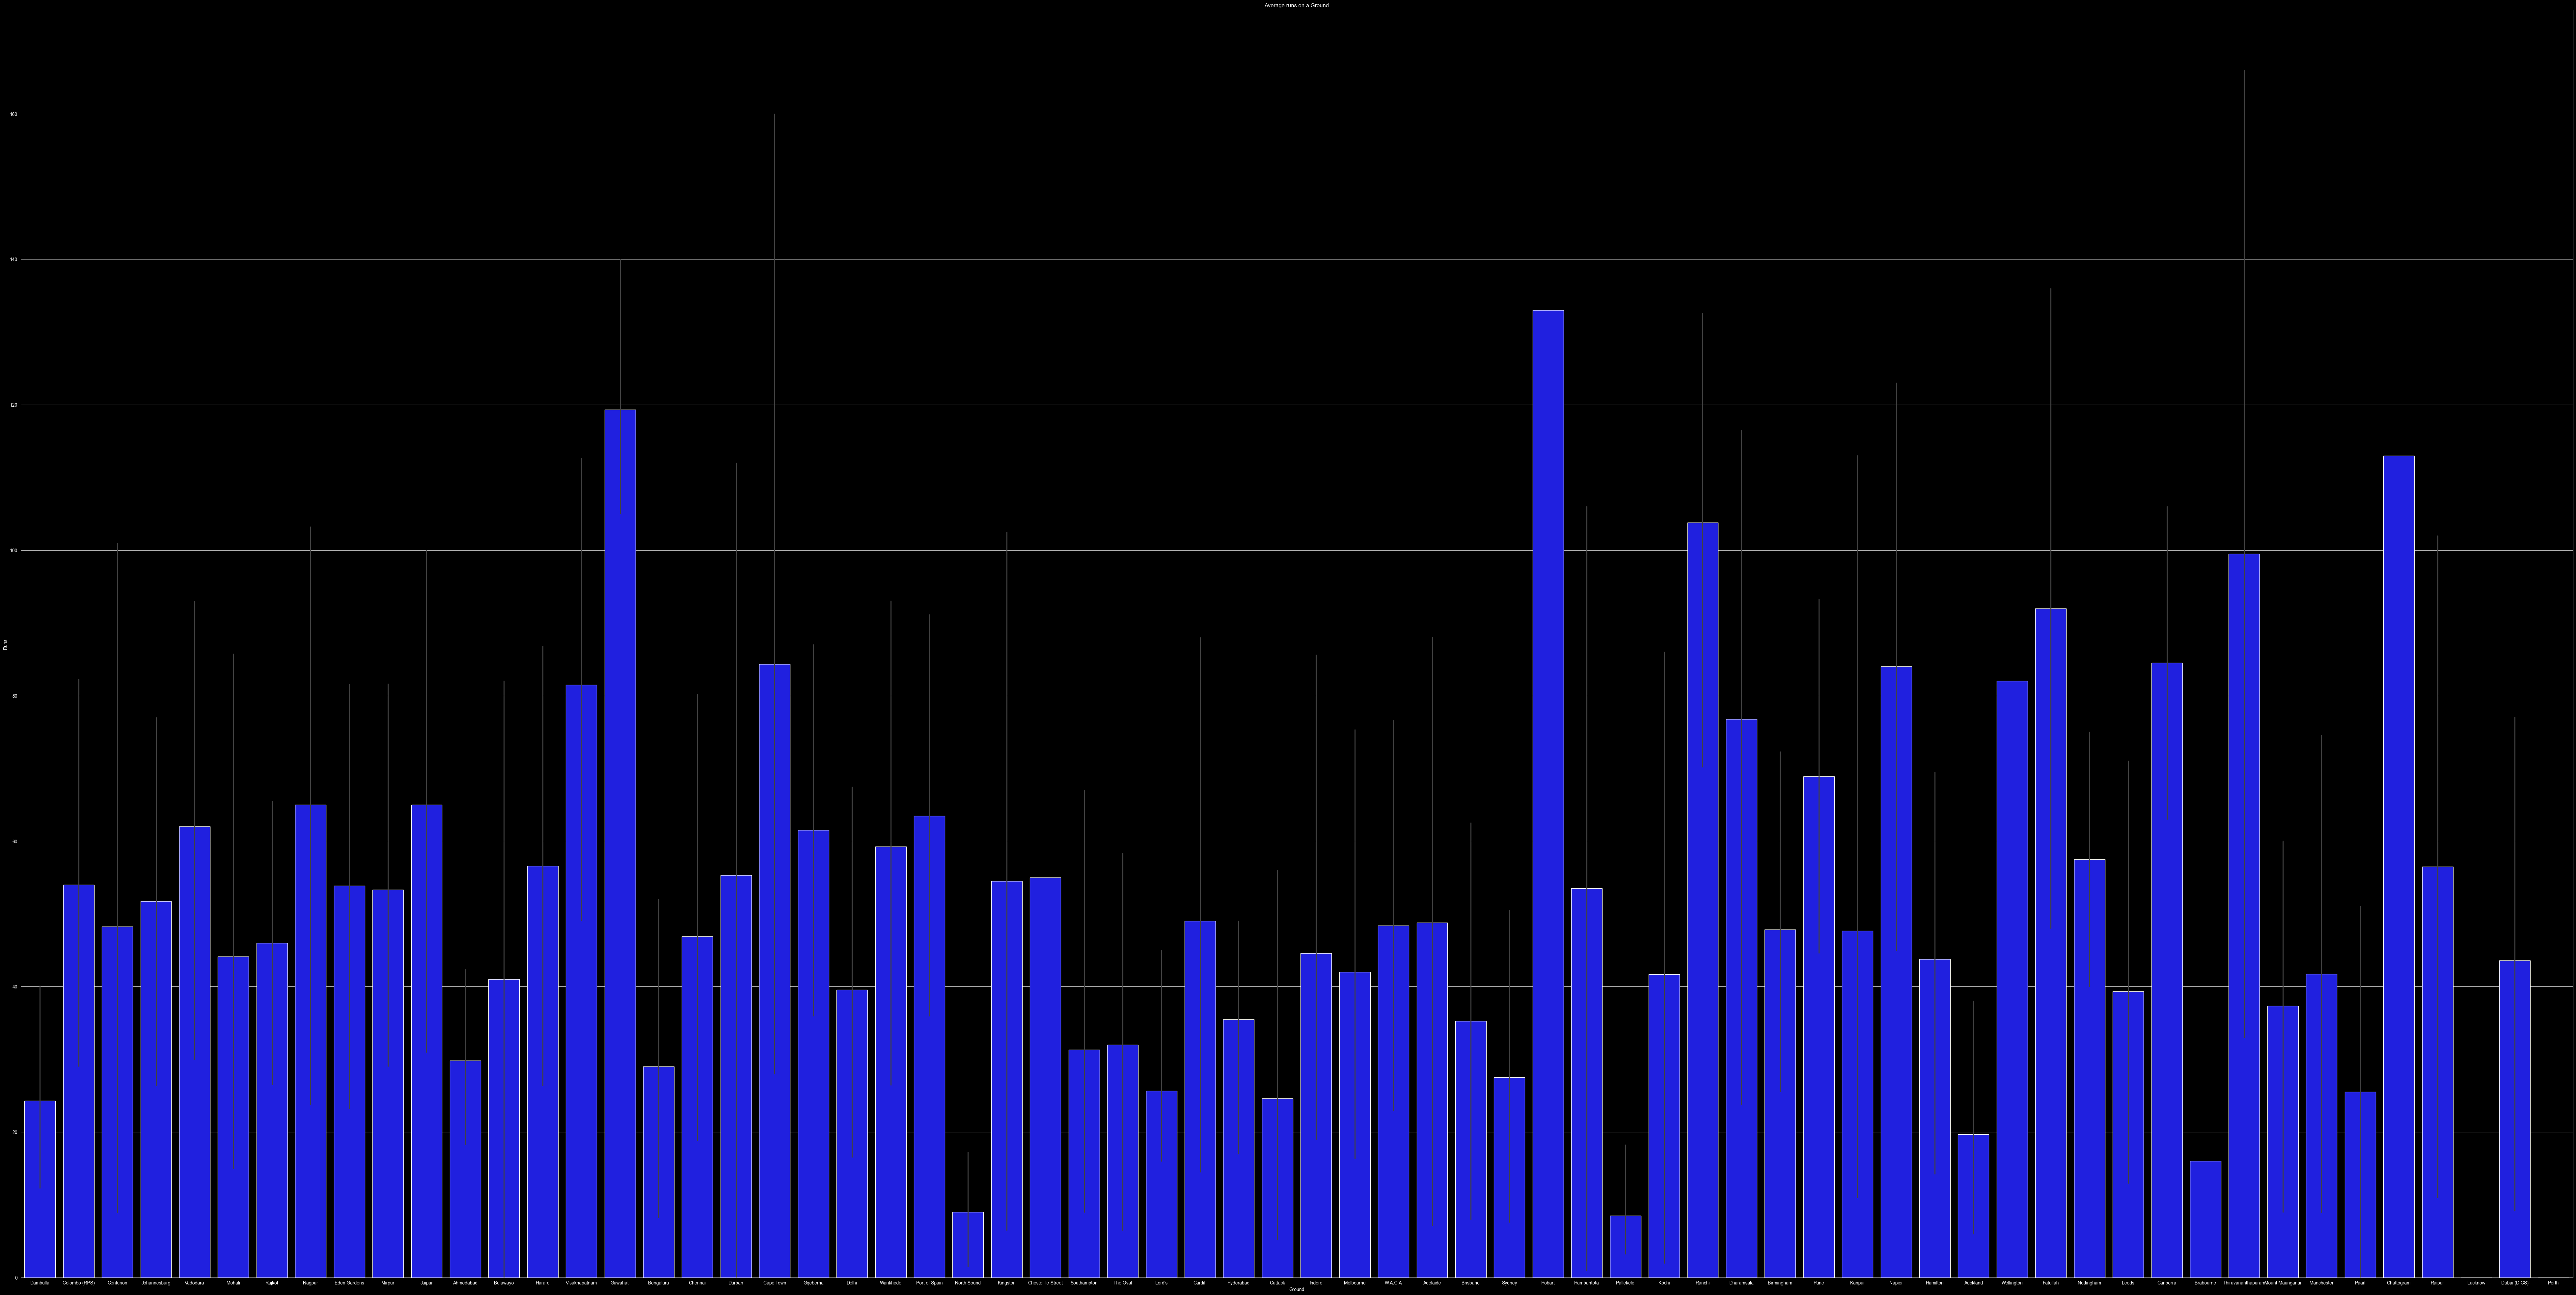

In [134]:
plt.figure(figsize=(100,50))
sns.barplot(data=df, x="Ground", y="Runs", color='blue')
plt.title('Average runs on a Ground')

In [135]:
ground_counts = (df['Ground'].value_counts())

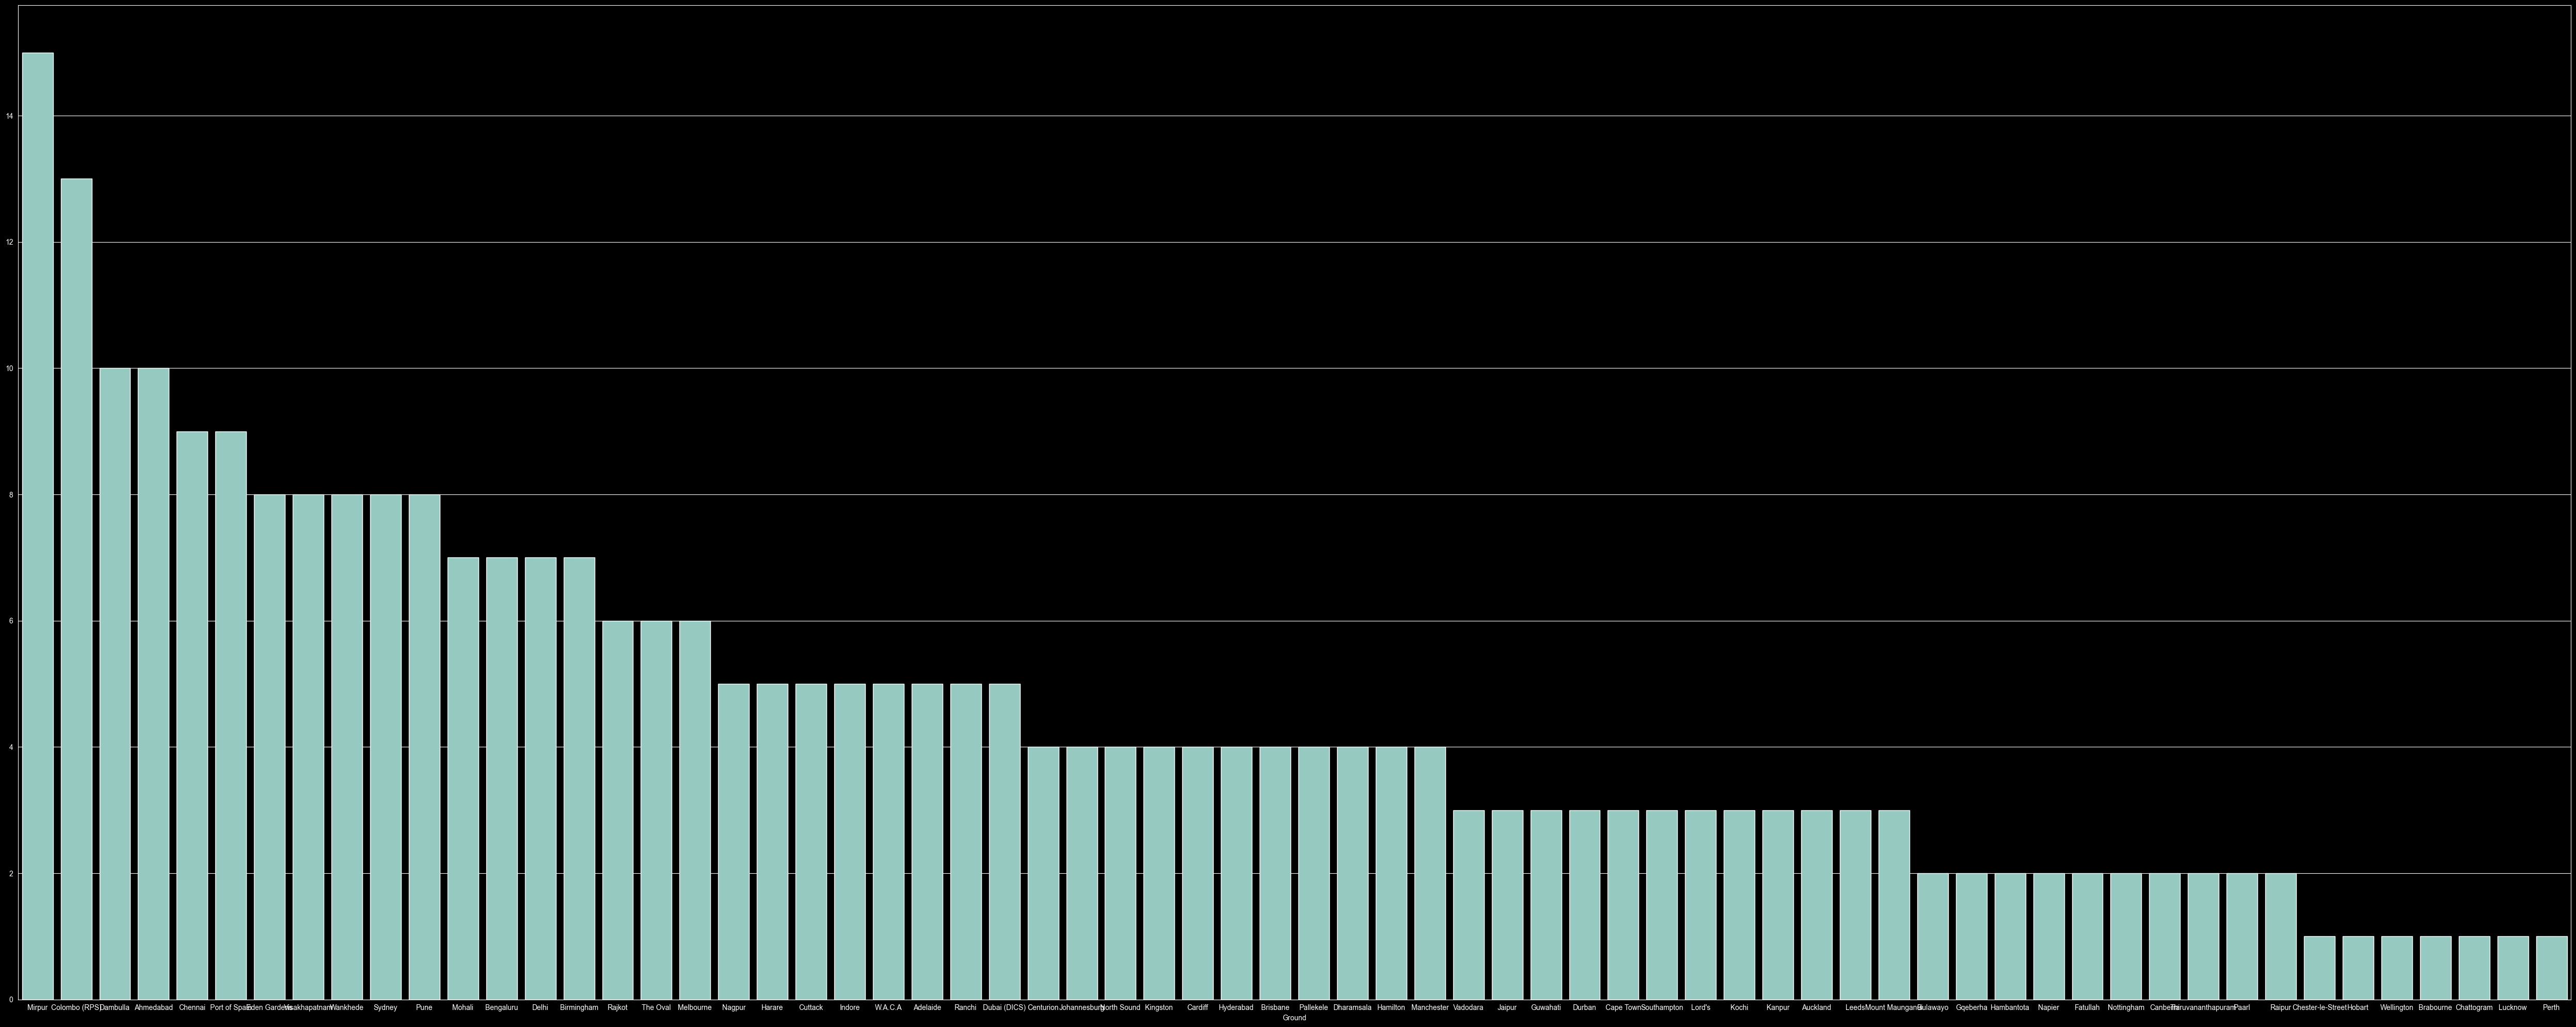

In [136]:
plt.figure(figsize=(50,20))
sns.barplot(y=ground_counts.values,x=ground_counts.index)
plt.tight_layout()
plt.show()

# Batting Position Analysis

<Axes: xlabel='Pos', ylabel='Runs'>

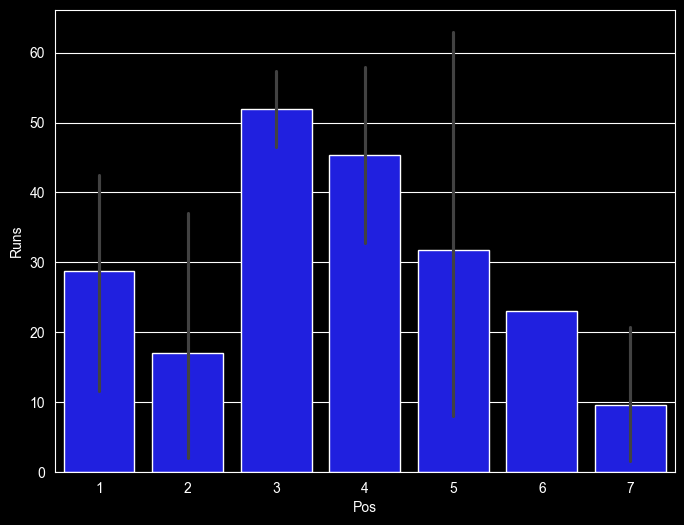

In [137]:
plt.figure(figsize=(8,6))
sns.barplot(data=df, x='Pos', y='Runs', color='blue')


# Not Out Analysis

<Axes: xlabel='NotOut', ylabel='count'>

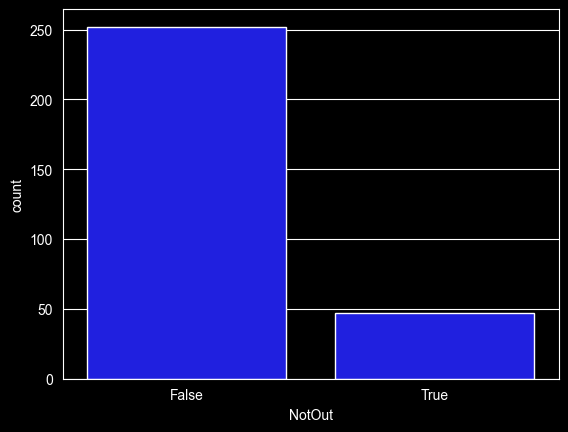

In [138]:
sns.countplot(x = df['NotOut'], color='blue')

# Strike Rate Analysis

<Axes: xlabel='SR', ylabel='Runs'>

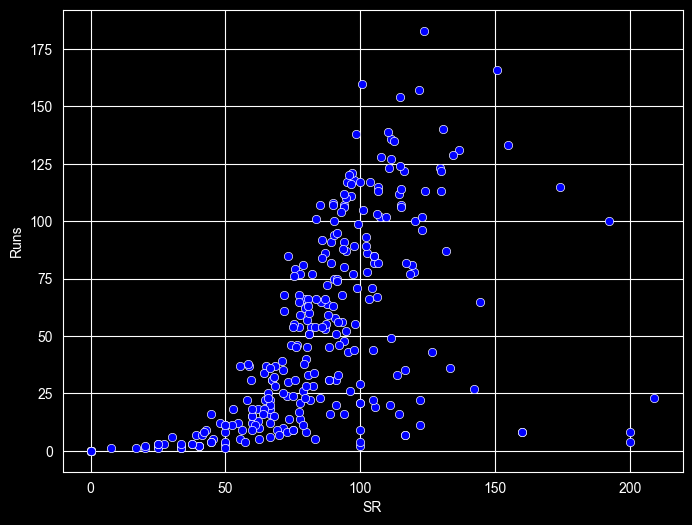

In [139]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='SR', y='Runs', color='blue')

# Balls Faced Analysis

<Axes: xlabel='BF', ylabel='Runs'>

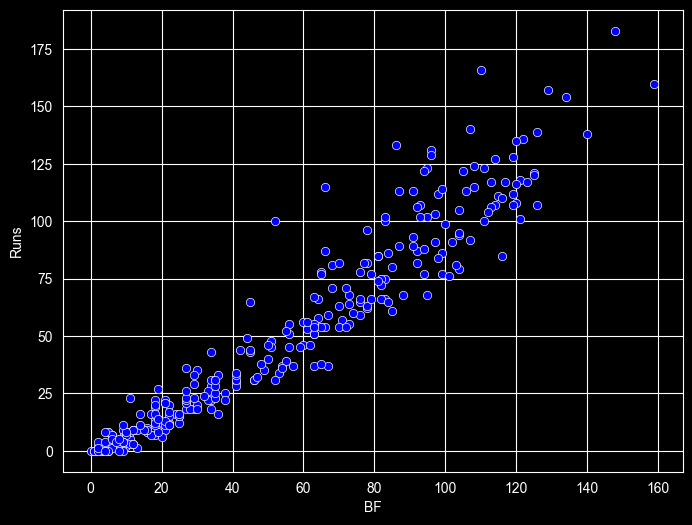

In [140]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='BF', y='Runs', color='blue')

# Boundary Analysis

<Axes: xlabel='4s', ylabel='Runs'>

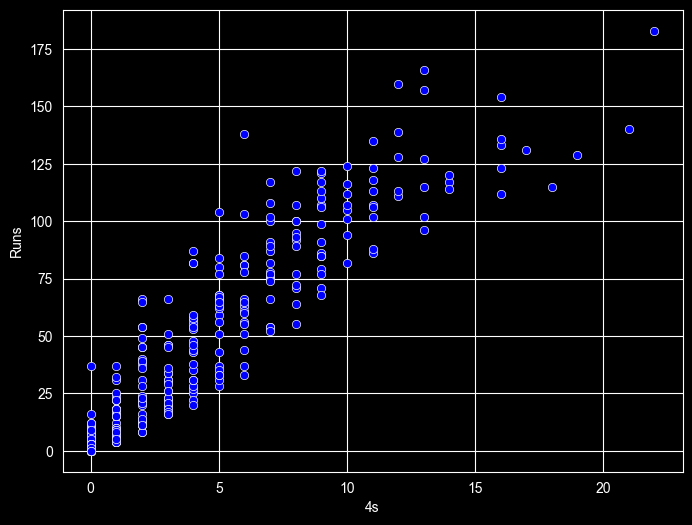

In [141]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='4s', y='Runs', color='blue')

<Axes: xlabel='6s', ylabel='Runs'>

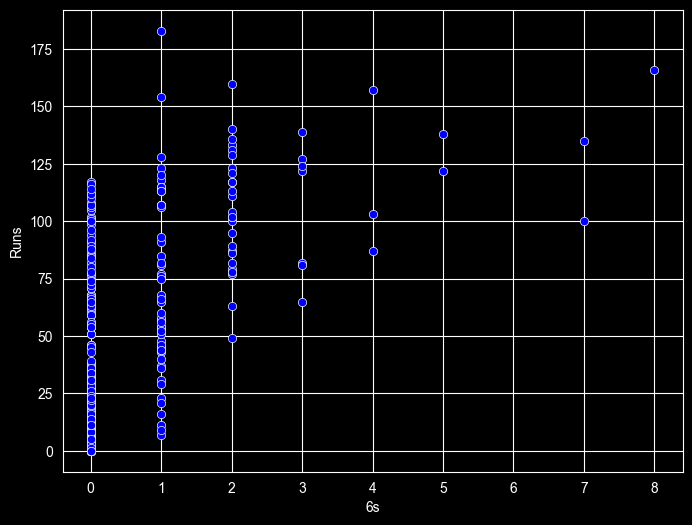

In [142]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='6s', y='Runs', color='blue')

<Axes: xlabel='4s', ylabel='6s'>

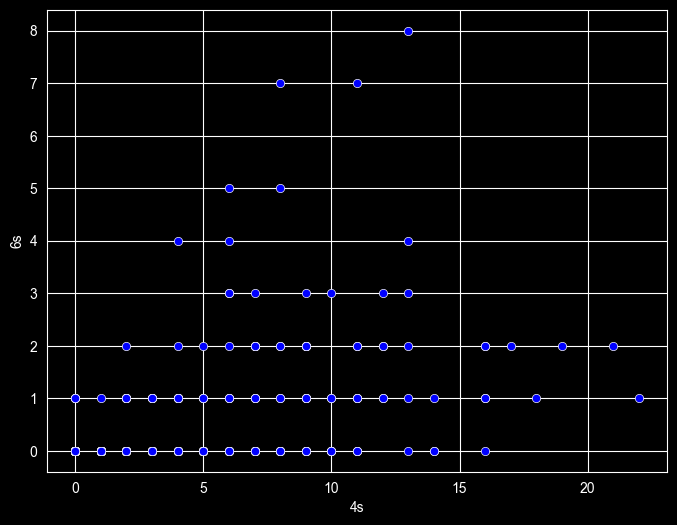

In [143]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='4s', y='6s', color='blue')

# Career Trend Analysis

In [144]:
df.head()

,Runs,Mins,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date,NotOut
0,12,33.0,22,1,0,54.54,2,lbw,1,v Sri Lanka,Dambulla,18 Aug 2008,False
1,37,82.0,67,6,0,55.22,2,caught,2,v Sri Lanka,Dambulla,20 Aug 2008,False
2,25,40.0,38,4,0,65.78,1,run out,1,v Sri Lanka,Colombo (RPS),24 Aug 2008,False
3,54,87.0,66,7,0,81.81,1,bowled,1,v Sri Lanka,Colombo (RPS),27 Aug 2008,False
4,31,45.0,46,3,1,67.39,1,lbw,2,v Sri Lanka,Colombo (RPS),29 Aug 2008,False


In [145]:
df['Start Date'] = pd.to_datetime(df['Start Date'],format='%d %b %Y')

In [146]:
df['Start Date'].dtype

dtype('<M8[us]')

In [148]:
df = df.sort_values('Start Date')

In [149]:
df[['Start Date', 'Runs']].head()

,Start Date,Runs
0,2008-08-18,12
1,2008-08-20,37
2,2008-08-24,25
3,2008-08-27,54
4,2008-08-29,31


In [150]:
df['Rolling5'] = df['Runs'].rolling(5).mean()
df['Rolling10'] = df['Runs'].rolling(10).mean()

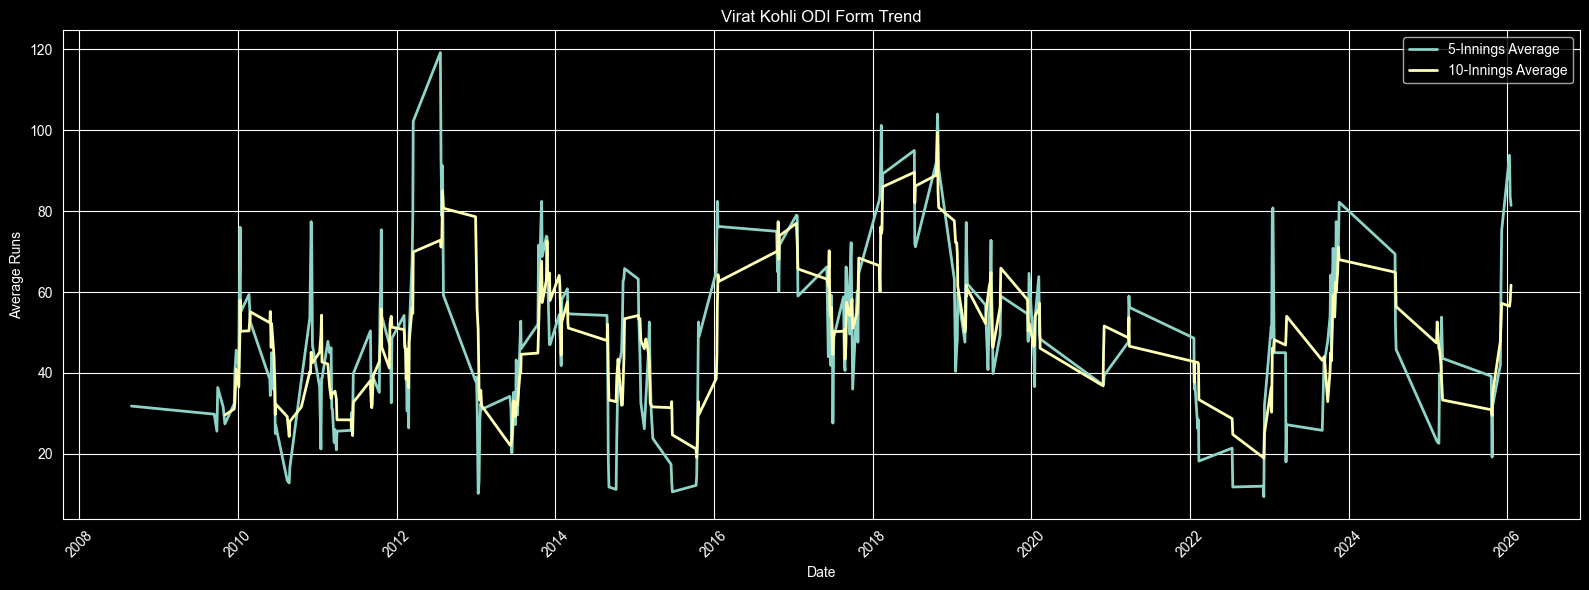

In [154]:
plt.figure(figsize=(16, 6))
plt.plot(df['Start Date'],df['Rolling5'],label='5-Innings Average',linewidth=2)
plt.plot(df['Start Date'],df['Rolling10'],label='10-Innings Average',linewidth=2)
plt.title('Virat Kohli ODI Form Trend')
plt.xlabel('Date')
plt.ylabel('Average Runs')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [155]:
df.head()

,Runs,Mins,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date,NotOut,Rolling5,Rolling10
0,12,33.0,22,1,0,54.54,2,lbw,1,v Sri Lanka,Dambulla,2008-08-18,False,NaN,NaN
1,37,82.0,67,6,0,55.22,2,caught,2,v Sri Lanka,Dambulla,2008-08-20,False,NaN,NaN
2,25,40.0,38,4,0,65.78,1,run out,1,v Sri Lanka,Colombo (RPS),2008-08-24,False,NaN,NaN
3,54,87.0,66,7,0,81.81,1,bowled,1,v Sri Lanka,Colombo (RPS),2008-08-27,False,NaN,NaN
4,31,45.0,46,3,1,67.39,1,lbw,2,v Sri Lanka,Colombo (RPS),2008-08-29,False,31.8,NaN


In [156]:
df['NotOut'] = df['NotOut'].astype(int)

In [157]:
df[['Rolling5','Rolling10']] = df[['Rolling5','Rolling10']].astype(float)

<Axes: >

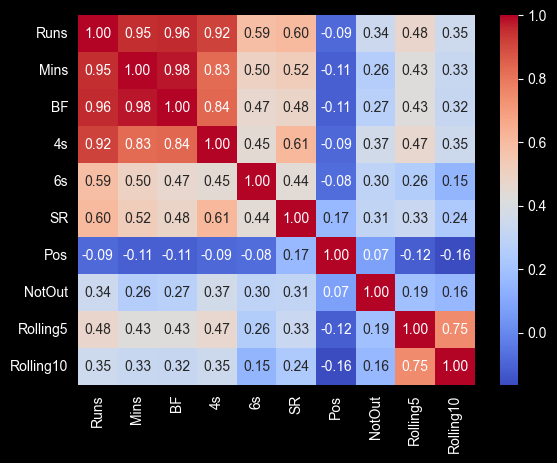

In [161]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm',fmt='.2f')